In [28]:
from google.colab import files
uploaded = files.upload()

Saving titanic.csv to titanic.csv


1.1: Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính.

In [37]:
# Import
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#đọc
df = pd.read_csv('titanic.csv', dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

# Kiểm tra
print("Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027")
df.head(12)
display(df.head())
df.info()
df.describe()


Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


1.2 Liệt kê danh sách 5 thuộc tính có số lượng giá trị rỗng nhiều nhất.

In [38]:
# Tính tổng số lượng và tỷ lệ % giá trị rỗng (missing values)[cite: 1]
total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)

# Gom nhóm thành DataFrame thống kê thiếu dữ liệu[cite: 1]
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])

# Hiển thị 5 thuộc tính có số lượng giá trị rỗng nhiều nhất[cite: 1]
print("Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027")
df.head(12)
missing_data.head(5)


Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


1.3: Vẽ biểu đồ khảo sát sự liên quan giữa thuộc tính Độ tuổi (age), Giới tính (sex)

Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027


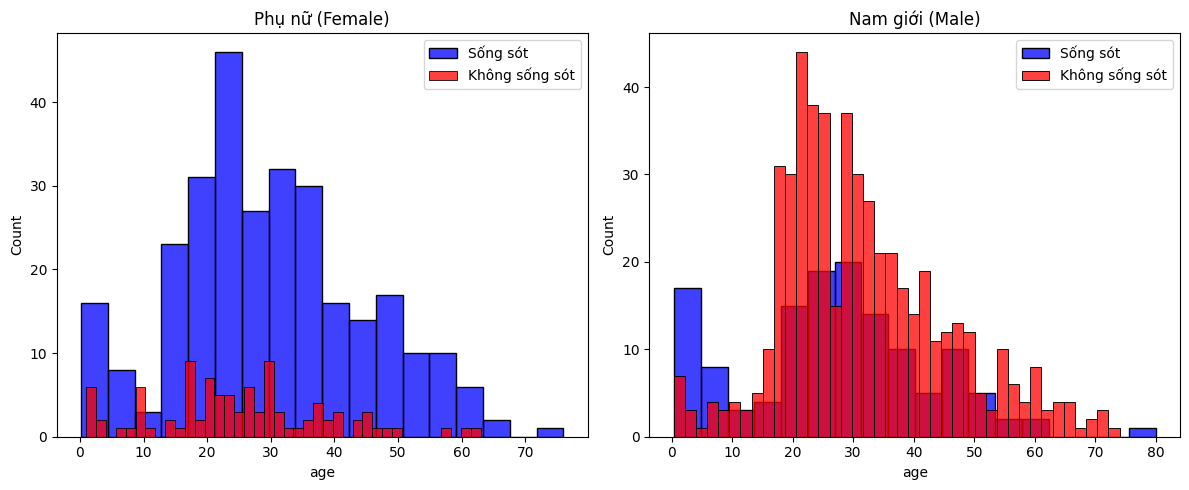

In [39]:
survived = 1
not_survived = 0
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']
print("Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027")
df.head(12)

# Biểu đồ cho Phụ nữ (Female)[cite: 1]
ax = sns.histplot(women[women['survived'] == survived].age.dropna(), bins=18, label='Sống sót', ax=axes[0], color='blue', kde=False)
ax = sns.histplot(women[women['survived'] == not_survived].age.dropna(), bins=40, label='Không sống sót', ax=axes[0], color='red', kde=False)
axes[0].legend()
axes[0].set_title('Phụ nữ (Female)')

# Biểu đồ cho Nam giới (Male)[cite: 1]
ax = sns.histplot(men[men['survived'] == survived].age.dropna(), bins=18, label='Sống sót', ax=axes[1], color='blue', kde=False)
ax = sns.histplot(men[men['survived'] == not_survived].age.dropna(), bins=40, label='Không sống sót', ax=axes[1], color='red', kde=False)
axes[1].legend()
axes[1].set_title('Nam giới (Male)')

plt.tight_layout()
plt.show()

1.4: Vẽ biểu đồ khảo sát sự liên quan giữa thuộc tính Cổng lên tàu (embarked) và loại vé
(pclass) với khả năng sống sót (survived), phân biệt theo Giới tính (sex)

Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027


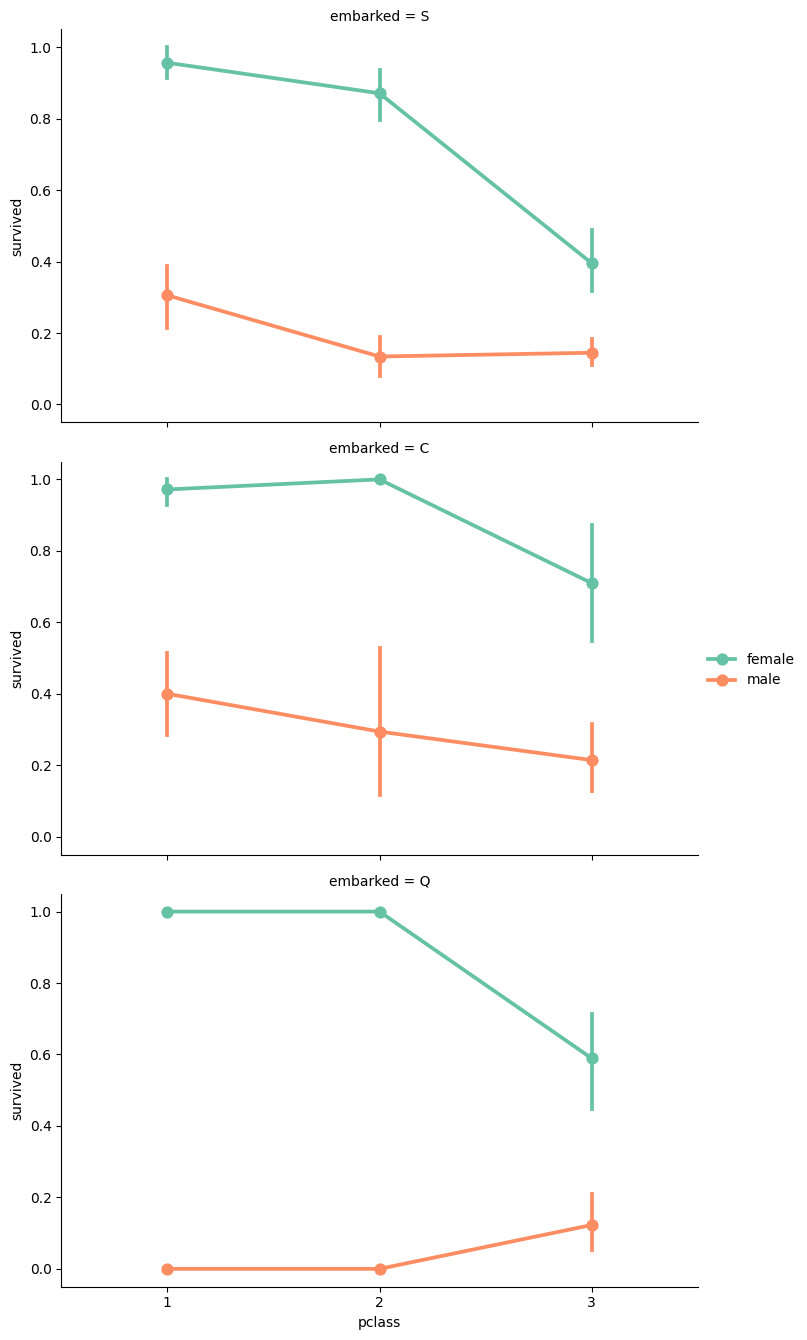

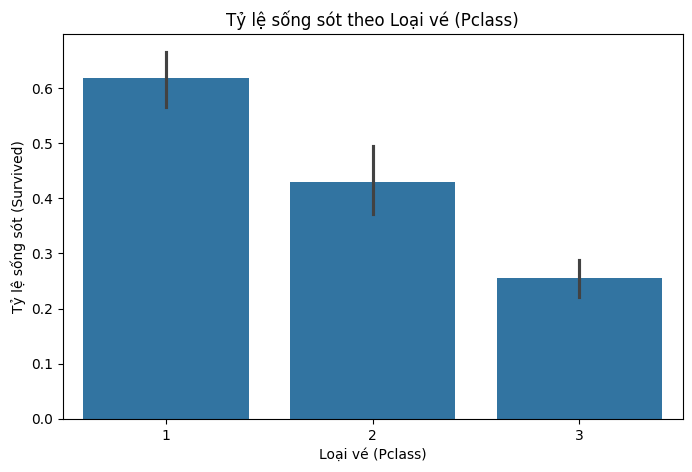

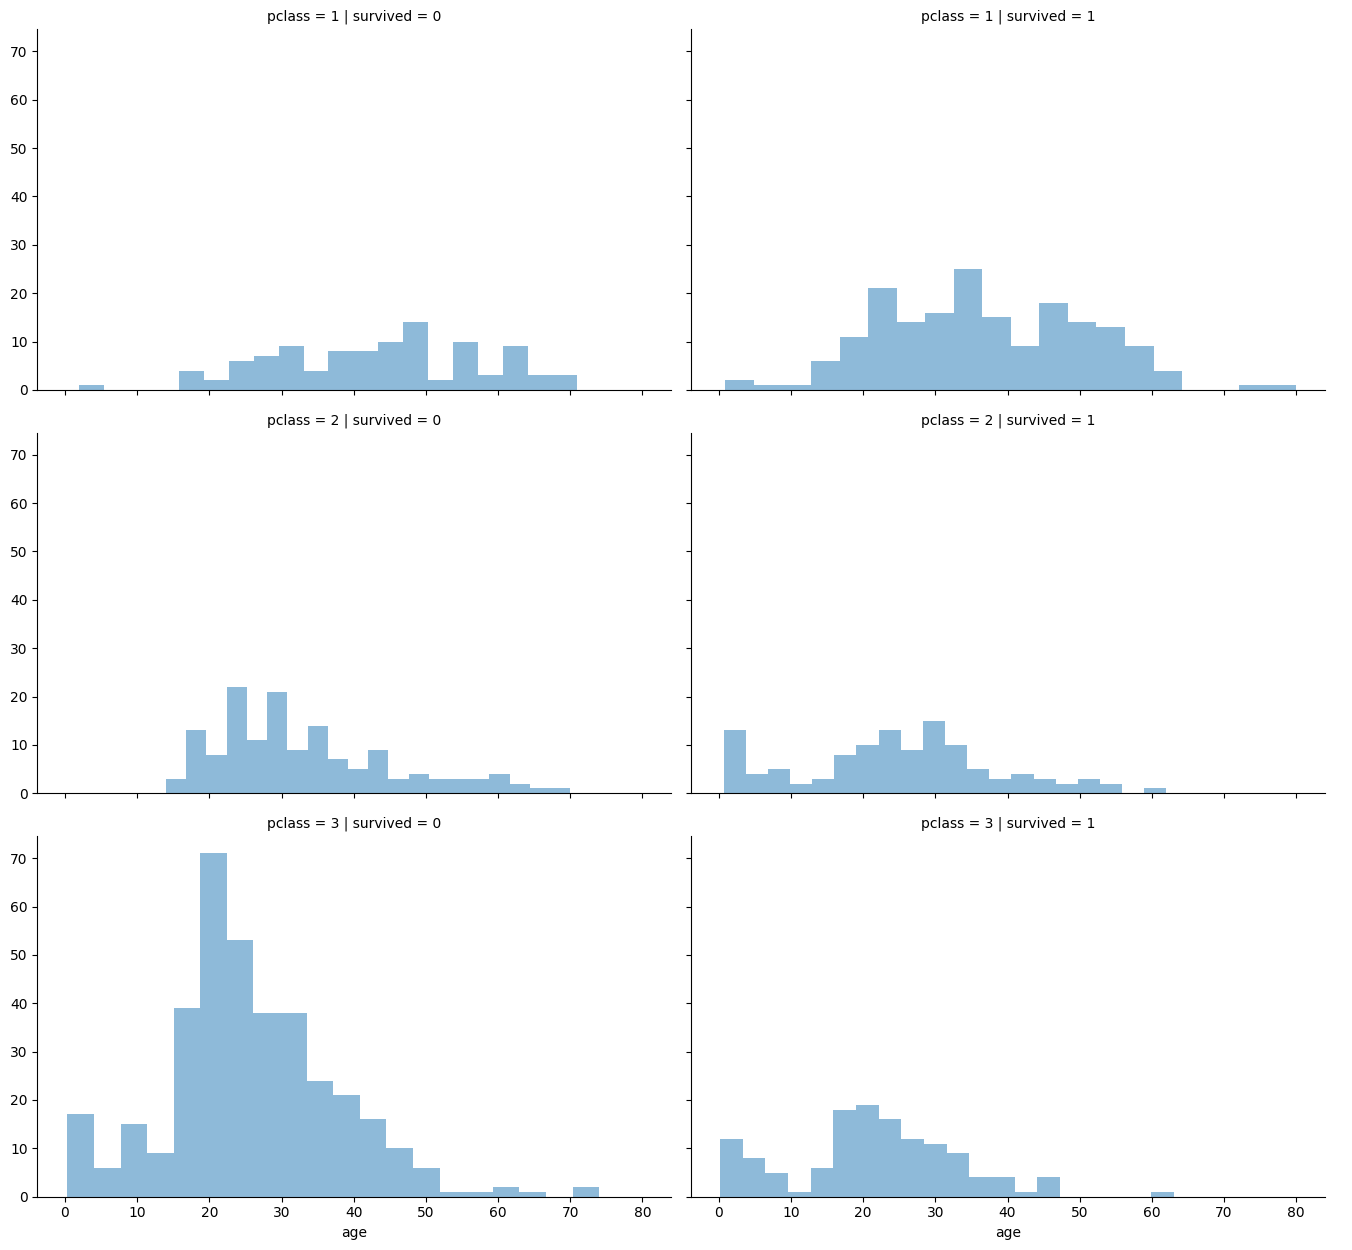

In [14]:
# Khảo sát mối quan hệ giữa embarked, pclass, sex và survived[cite: 1]
print("Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027")
df.head(12)
facetgrid = sns.FacetGrid(df, row='embarked', height=4.5, aspect=1.6)
facetgrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette='Set2', order=[1, 2, 3], hue_order=['female', 'male'])
facetgrid.add_legend()
plt.show()
# Biểu đồ cột thể hiện tỷ lệ sống sót theo loại vé (Pclass)[cite: 2]
plt.figure(figsize=(8, 5))
sns.barplot(x='pclass', y='survived', data=df)
plt.title('Tỷ lệ sống sót theo Loại vé (Pclass)')
plt.ylabel('Tỷ lệ sống sót (Survived)')
plt.xlabel('Loại vé (Pclass)')
plt.show()
# Lưới biểu đồ phân phối độ tuổi (age) theo khả năng sống sót và loại vé[cite: 3]
grid = sns.FacetGrid(df, col='survived', row='pclass', height=4.2, aspect=1.6)
grid.map(plt.hist, 'age', alpha=0.5, bins=20)
grid.add_legend()
plt.show()

1.5: Thống kê số người đi cùng (anh chị em/vợ chồng hoặc cha mẹ/con cái) và khảo sát
sự liên quan với thuộc tính quyết định

Thống kê số lượng hành khách đi một mình / đi cùng người thân:
not_alone
1    790
0    519
Name: count, dtype: int64
Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027


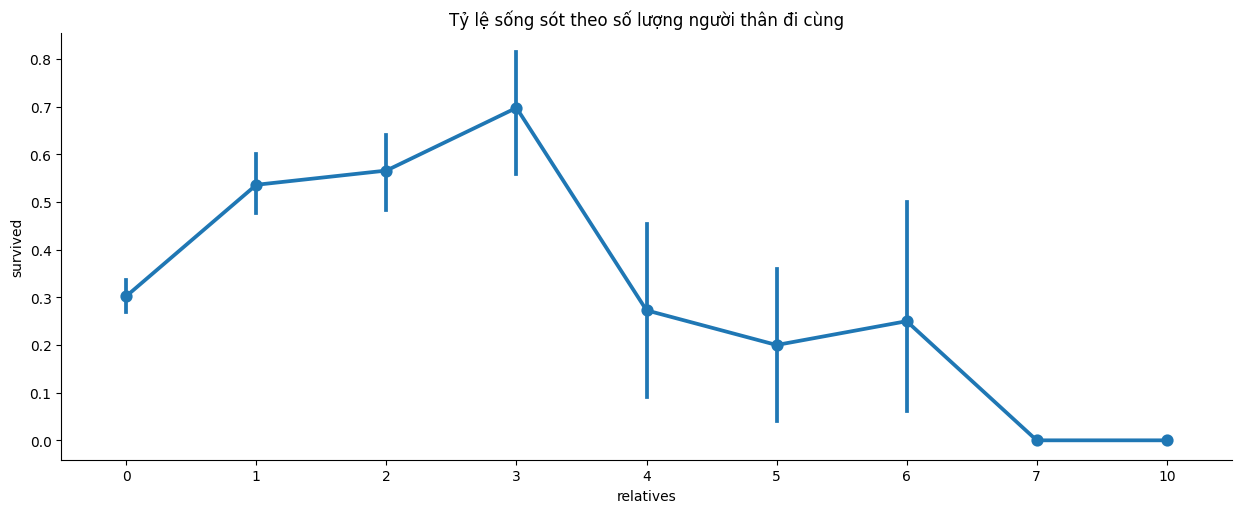

In [15]:
# Tính toán số người đi cùng[cite: 1]
for dataset in [df]:
    dataset['relatives'] = dataset['sibsp'] + dataset['parch']
    dataset.loc[dataset['relatives'] > 0, 'not_alone'] = 0
    dataset.loc[dataset['relatives'] == 0, 'not_alone'] = 1
    dataset['not_alone'] = dataset['not_alone'].astype(int)

# Thống kê số người đi một mình và đi cùng người thân[cite: 1]
print("Thống kê số lượng hành khách đi một mình / đi cùng người thân:")
print(df['not_alone'].value_counts())

# Vẽ biểu đồ thể hiện mối quan hệ giữa số lượng người thân và khả năng sống sót[cite: 1]
print("Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027")
df.head(12)
axes = sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')
plt.title('Tỷ lệ sống sót theo số lượng người thân đi cùng')
plt.show()

1.6: Tiền xử lí dữ liệu

In [30]:
#6.1 Xử lý thuộc tính cabin
print("-" * 30)
import re

# Khai báo từ điển ánh xạ ký tự boong sang số
deck = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}

for dataset in [df]:
    dataset['cabin'] = dataset['cabin'].fillna("U0")
    dataset['deck'] = dataset['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
    dataset['deck'] = dataset['deck'].map(deck)
    dataset['deck'] = dataset['deck'].fillna(0)
    dataset['deck'] = dataset['deck'].astype(int)

# Xóa cột cabin sau khi đã trích xuất xong
df = df.drop(['cabin'], axis=1)

------------------------------


In [31]:
# 6.2 Xem xét và xóa các thuộc tính không cần thiết
print("-" * 30)
# Kiểm tra mô tả thuộc tính ticket
print(df['ticket'].describe())
print("-" * 30)

# Thực hiện xóa các thuộc tính không cần thiết
df = df.drop(['ticket'], axis=1)
df = df.drop(['boat'], axis=1)
df = df.drop(['body'], axis=1)
df = df.drop(['home.dest'], axis=1)

print("Đã xóa các thuộc tính không cần thiết thành công!")

------------------------------
count         1309
unique         929
top       CA. 2343
freq            11
Name: ticket, dtype: object
------------------------------
Đã xóa các thuộc tính không cần thiết thành công!


In [34]:
#6.3 Điền giá trị còn thiếu vào thuộc tính độ tuổi (age)
print("-" * 30)
# Điền giá trị còn thiếu cho cột age bằng số liệu ngẫu nhiên dựa trên mean và std
for dataset in [df]:
    mean = df["age"].mean()
    std = df["age"].std()
    is_null = dataset["age"].isnull().sum()

    # Tạo giá trị ngẫu nhiên giữa mean - std và mean + std
    rand_age = np.random.randint(mean - std, mean + std, size=is_null)

    # Điền vào các vị trí NaN
    age_slice = dataset["age"].copy()
    age_slice[np.isnan(age_slice)] = rand_age
    dataset["age"] = age_slice
    dataset["age"] = df["age"].astype(int)

# Kiểm tra lại số lượng giá trị null của age (phải bằng 0)
print("Số lượng giá trị null còn lại của age:", df["age"].isnull().sum())


------------------------------
Số lượng giá trị null còn lại của age: 0


In [36]:
# 6.4 Điền giá trị còn thiếu vào thuộc tính Cổng lên tàu (embarked)
print("Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027")
# Xem thông tin thống kê của embarked
print(df['embarked'].describe())
print("-" * 30)

# Điền giá trị phổ biến nhất ('S') vào các ô còn thiếu
common_value = 'S'
for dataset in [df]:
    dataset['embarked'] = dataset['embarked'].fillna(common_value)

print("Đã điền xong giá trị thiếu cho embarked!")

Họ và tên: Nguyễn Gia Huy - MSSV: 6451071027
count     1309
unique       3
top          S
freq       916
Name: embarked, dtype: object
------------------------------
Đã điền xong giá trị thiếu cho embarked!
